# DSCI 552 — Homework 7
**Alan Nhan** 
ID: 3907-9934-60
https://github.com/nhvn

### AI Use Disclosure

ChatGPT was used to help clarify machine learning concepts, understand the assignment requirements, and review statistical interpretations.

**Example prompts:**
- "Why is exact match accuracy stricter than Hamming loss when evaluating multi-label classification?"
- "Why should SMOTE be applied within each cross-validation fold instead of before cross-validation?"
- "How does the choice of k affect K-Means clustering and the resulting Hamming distance?"
- "Can you make this more concise and professional by rewording it?"

In [1]:
import io, urllib.request, zipfile, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

SEED = 552
DATA, OUT = Path("data/Frogs_MFCCs.csv"), Path("results")
OUT.mkdir(exist_ok=True)
LABELS = ["Family", "Genus", "Species"]
pd.set_option("display.precision", 4)
warnings.filterwarnings("ignore", message="A worker stopped")  # benign loky executor-resize notice

## 1. Multi-class and Multi-label Classification Using SVMs
### 1(a) Data and 70/30 split
The 22 `MFCCs_*` columns are the predictors; `Family`, `Genus`, `Species` are the targets; `RecordID` is an identifier and is dropped. The split is random (seeded) and stratified on `Species` so that rare species appear in both sets; because species determines genus and family, all three labels stay balanced across the split. The same split is used for every supervised model.

In [2]:
if not DATA.exists():  # download from UCI only if the local copy is missing
    url = "https://archive.ics.uci.edu/static/public/406/anuran+calls+mfccs.zip"
    with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())) as z:
        DATA.parent.mkdir(exist_ok=True)
        DATA.write_bytes(z.read("Frogs_MFCCs.csv"))

df = pd.read_csv(DATA)
X, Y = df.filter(like="MFCCs"), df[LABELS]          # RecordID excluded
X_tr, X_te, Y_tr, Y_te = train_test_split(
    X, Y, train_size=0.7, random_state=SEED, stratify=Y["Species"])

print(f"Full data: {df.shape}, predictors: {X.shape[1]}, missing values: {df.isna().sum().sum()}")
print(f"Train: {len(X_tr)}  Test: {len(X_te)}")
pd.DataFrame({"Classes": Y.nunique(), "Smallest class (train)": Y_tr.apply(lambda s: s.value_counts().min()),
              "Largest class (train)": Y_tr.apply(lambda s: s.value_counts().max())})

Full data: (7195, 26), predictors: 22, missing values: 0
Train: 5036  Test: 2159


,Classes,Smallest class (train),Largest class (train)
Family,4,48,3093
Genus,8,48,2904
Species,10,48,2434


### 1(b)i Evaluation metrics
For $n$ observations with $L=3$ labels, let $y_{i\ell}$ and $\hat y_{i\ell}$ be the true and predicted class of label $\ell$ for observation $i$.

- **Exact match** (subset accuracy): $\frac{1}{n}\sum_i \mathbf 1[\hat y_{i\ell}=y_{i\ell}\ \forall \ell]$, the share of observations whose family, genus, *and* species are all correct.
- **Hamming loss**: $\frac{1}{nL}\sum_i\sum_\ell \mathbf 1[\hat y_{i\ell}\neq y_{i\ell}]$, the fraction of individual label predictions that are wrong.
- **Hamming score**: $1-\text{Hamming loss}$, the label-wise accuracy averaged over the three labels.
- **Hamming distance** (used in Problem 2): $\frac{1}{n}\sum_i\sum_\ell \mathbf 1[\hat y_{i\ell}\neq y_{i\ell}] = L\cdot\text{Hamming loss}$, the average number of wrong labels per observation (0–3).

These are the label-wise definitions for multi-*output* targets. In the binary-indicator multi-label setting (Sorower), "Hamming score" sometimes means the set-based Jaccard accuracy $|Y_i\cap\hat Y_i|/|Y_i\cup\hat Y_i|$; that is not used here. Exact match is the strictest metric, since one wrong label makes the whole observation count as wrong.

In [3]:
def ml_metrics(Y_true, Y_pred):
    # Label-wise multi-output metrics; rows = observations, columns = labels
    err = np.asarray(Y_true) != np.asarray(Y_pred)
    return {"Exact match": (~err.any(axis=1)).mean(), "Hamming score": 1 - err.mean(),
            "Hamming loss": err.mean(), "Hamming distance": err.sum(axis=1).mean()}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

def fit_per_label(make_model, grid):
    # Binary relevance: tune one model per label with 10-fold CV on the training set only
    rows, pred = [], {}
    for lab in LABELS:
        gs = GridSearchCV(make_model(), grid, cv=cv, scoring="accuracy", n_jobs=-1).fit(X_tr, Y_tr[lab])
        pred[lab] = gs.predict(X_te)    # test set is touched only after tuning
        best = {k.split("__")[-1]: v for k, v in gs.best_params_.items()}
        rows.append({"Label": lab, **best, "CV acc": gs.best_score_,
                     "Test acc": (pred[lab] == Y_te[lab]).mean()})
    return pd.DataFrame(rows).set_index("Label"), ml_metrics(Y_te, pd.DataFrame(pred)[LABELS])

### 1(b)ii Gaussian-kernel SVM (one-vs-rest)
Each label gets `OneVsRestClassifier(SVC(kernel="rbf"))`. Standardization sits inside the pipeline, so it is refit on each CV training fold. A pilot fit on the training set (following the footnote) showed $\gamma\ge1$ memorizes the data (100% training accuracy) and is about 10× slower, while $C\le0.1$ underfits. So the grid uses $C\in\{10^0,\dots,10^4\}$ on a log scale and $\gamma\in[0.005,0.2]$, with $\gamma=1/(2\sigma^2)$, i.e. $\sigma\approx1.6$–$10$.

In [4]:
rbf = lambda: Pipeline([("scale", StandardScaler()),
                        ("svm", OneVsRestClassifier(SVC(kernel="rbf")))])
rbf_grid = {"svm__estimator__C": np.logspace(0, 4, 5),
            "svm__estimator__gamma": [0.005, 0.01, 0.02, 0.05, 0.1, 0.2]}
rbf_params, rbf_metrics = fit_per_label(rbf, rbf_grid)
rbf_params.to_csv(OUT / "p1_rbf_params.csv")
rbf_params

,C,gamma,CV acc,Test acc
Label,,,,
Family,10.0,0.05,0.9929,0.9912
Genus,10.0,0.05,0.9905,0.9898
Species,10.0,0.05,0.9899,0.9893


### 1(b)iii L1-penalized linear SVM
`LinearSVC(penalty="l1", dual=False)` (squared hinge loss, liblinear; one-vs-rest by construction) on standardized predictors, with $C\in\{10^{-3},10^{-2},\dots,10^{2}\}$ (log-scale increments; $C=10^{-3}$ still gives >70% training accuracy in the pilot) chosen by 10-fold CV. A solver tolerance of $10^{-3}$ ensures convergence at large $C$ on the SMOTE-enlarged training folds.

In [5]:
l1_svm = lambda: LinearSVC(penalty="l1", dual=False, tol=1e-3, max_iter=10000, random_state=SEED)
l1 = lambda: Pipeline([("scale", StandardScaler()), ("svm", l1_svm())])
l1_grid = {"svm__C": np.logspace(-3, 2, 6)}
l1_params, l1_metrics = fit_per_label(l1, l1_grid)
l1_params.to_csv(OUT / "p1_l1_params.csv")
l1_params

,C,CV acc,Test acc
Label,,,
Family,10.0,0.9386,0.9328
Genus,10.0,0.9521,0.9546
Species,1.0,0.9575,0.9592


### 1(b)iv L1 SVM with SMOTE
SMOTE runs inside an `imblearn` pipeline after scaling. During CV, only the 9 training folds are oversampled, and the validation fold and the test set are never resampled. The rarest class (*Rhinella granulosa*/Bufonidae) has 48 training samples and so at least 43 in every CV training fold, so SMOTE's default `k_neighbors=5` is valid for all labels.

In [6]:
smote = lambda: ImbPipeline([("scale", StandardScaler()),
                             ("smote", SMOTE(k_neighbors=5, random_state=SEED)),
                             ("svm", l1_svm())])
sm_params, sm_metrics = fit_per_label(smote, l1_grid)
sm_params.to_csv(OUT / "p1_l1_smote_params.csv")
sm_params

,C,CV acc,Test acc
Label,,,
Family,1.0,0.9297,0.9199
Genus,100.0,0.9245,0.9097
Species,0.1,0.9547,0.9606


In [7]:
summary = pd.DataFrame({"RBF SVM": rbf_metrics, "L1 SVM": l1_metrics,
                        "L1 SVM + SMOTE": sm_metrics}).T.drop(columns="Hamming distance")
summary.to_csv(OUT / "p1_test_metrics.csv")
summary

,Exact match,Hamming score,Hamming loss
RBF SVM,0.9870,0.9901,0.0099
L1 SVM,0.9162,0.9489,0.0511
L1 SVM + SMOTE,0.8652,0.9301,0.0699


**Conclusions.** The Gaussian SVM is clearly best (exact match 0.987, Hamming loss 0.010). The tuned values ($C=10,\ \gamma=0.05$) lie inside the grid, and CV and test accuracy agree closely, so there is little overfitting. The L1 linear SVM is noticeably worse (exact match 0.916): the classes are not linearly separable in MFCC space, and an error on any one label breaks the exact match. Genus selects the largest $C$ in the grid, but at that point the penalty is already weak and the pilot's training accuracy had plateaued for $C\ge1$. SMOTE *lowered* the overall metrics (exact match 0.865). Oversampling the rare classes moves the linear boundaries toward them, which trades accuracy on the dominant classes (e.g. *Adenomera*/Leptodactylidae) for minority-class recall. Exact match and Hamming loss weight every observation equally, so they reward majority-class accuracy; SMOTE is worthwhile only if minority-class recall matters more than overall accuracy.

## 2. K-means Clustering on a Multi-class, Multi-label Dataset
### 2(a) Choosing $k$ (50 Monte Carlo runs)
K-means is fit on all 7,195 observations using only the MFCC features. The features are left unscaled because they are already normalized to $[-1,1]$. In each run $m=0,\dots,49$ (seed $552+m$), K-means (`n_init=5`) is fit for every $k=2,\dots,50$, and $k$ is chosen to maximize the **silhouette**. To keep the 2,450 silhouette evaluations cheap, the silhouette is computed on a random subsample of 3,000 observations; the subsample is fixed within a run (seed $552+m$), so every $k$ is scored on the same points. A full-data check costs about 8× more per evaluation. The silhouette is undefined at $k=1$ (there is no "nearest other cluster"), so $k=1$ cannot be scored and is excluded. The data's known 4/8/10-class structure also rules it out as a sensible choice.

### 2(b) Majority labels, 2(c) Hamming metrics
In each cluster, the majority family, genus, and species are read from the true labels, which are used only after clustering. Ties go to the alphabetically first class (`Series.mode()` returns sorted modes). Every observation receives its cluster's majority triplet, and the metrics from 1(b)i are computed against the true triplets.

In [8]:
X_all, Y_all = X.to_numpy(), Y.reset_index(drop=True)
K_RANGE = range(2, 51)

def mc_run(m):
    seed = SEED + m
    with threadpool_limits(1):                     # avoid thread oversubscription across workers
        fits = [KMeans(k, n_init=5, random_state=seed).fit_predict(X_all) for k in K_RANGE]
        sil = np.array([silhouette_score(X_all, c, sample_size=3000, random_state=seed) for c in fits])
    best = int(sil.argmax())
    cl = fits[best]
    triplets = Y_all.groupby(cl)[LABELS].agg(lambda s: s.mode().iloc[0])   # majority, alphabetical ties
    Y_hat = triplets.loc[cl].to_numpy()
    return {"run": m, "seed": seed, "k": K_RANGE[best], "silhouette": sil[best],
            **ml_metrics(Y_all, Y_hat)}, sil, triplets

out = Parallel(n_jobs=-1)(delayed(mc_run)(m) for m in range(50))
runs = pd.DataFrame([o[0] for o in out]).set_index("run")
sil_curves = np.vstack([o[1] for o in out])
runs.to_csv(OUT / "p2_monte_carlo_runs.csv")
print(f"Completed runs: {len(runs)};  chosen k counts: {runs['k'].value_counts().sort_index().to_dict()}")

Completed runs: 50;  chosen k counts: {4: 49, 5: 1}


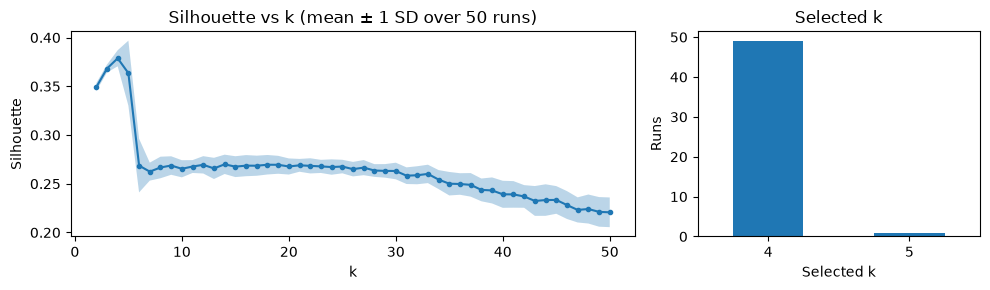

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3), gridspec_kw={"width_ratios": [2, 1]})
mu, sd = sil_curves.mean(0), sil_curves.std(0, ddof=1)
ax[0].plot(K_RANGE, mu, marker=".")
ax[0].fill_between(K_RANGE, mu - sd, mu + sd, alpha=0.3)
ax[0].set(xlabel="k", ylabel="Silhouette", title="Silhouette vs k (mean ± 1 SD over 50 runs)")
runs["k"].value_counts().sort_index().plot.bar(ax=ax[1], rot=0)
ax[1].set(xlabel="Selected k", ylabel="Runs", title="Selected k")
fig.tight_layout(); fig.savefig(OUT / "p2_silhouette.png", dpi=150); plt.show()

In [10]:
print("Majority-label triplets, run 0 (k = %d):" % runs.loc[0, "k"])
out[0][2].rename_axis("Cluster")

Majority-label triplets, run 0 (k = 4):


,Family,Genus,Species
Cluster,,,
0,Hylidae,Hypsiboas,HypsiboasCordobae
1,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
2,Hylidae,Hypsiboas,HypsiboasCordobae
3,Leptodactylidae,Adenomera,AdenomeraAndre


In [11]:
cols = ["k", "silhouette", "Hamming distance", "Hamming score", "Hamming loss", "Exact match"]
mc_summary = runs[cols].agg(["mean", "std"]).T.rename(columns={"std": "std (ddof=1)"})
mc_summary.to_csv(OUT / "p2_summary.csv")
mc_summary

,mean,std (ddof=1)
k,4.0200,0.1414
silhouette,0.3797,0.0041
Hamming distance,0.6793,0.0498
Hamming score,0.7736,0.0166
Hamming loss,0.2264,0.0166
Exact match,0.7435,0.0271


**Interpretation.** The silhouette peaks sharply at $k=4$ (chosen in 49/50 runs), and results are very stable across runs. The average Hamming distance is $0.68 \pm 0.05$ wrong labels per observation, i.e. Hamming loss $0.226 \pm 0.017$ and Hamming score $0.774 \pm 0.017$ (mean ± sample SD over 50 runs). Because each cluster takes the label of its dominant species, only the large classes (*Adenomera*, *Hypsiboas*) ever become cluster majorities; in run 0, two of the four clusters even map to the same triplet. Every call from a minority species is therefore mislabeled, which is why unsupervised clustering falls far short of the supervised SVMs (Hamming loss 0.010–0.070).

## 3. ISLR 12.6.2
*Exercise (ISLR 2nd ed., paraphrased):* Four observations have the dissimilarity matrix below. (a) Sketch the complete-linkage dendrogram, showing fusion heights and leaf labels; (b) repeat with single linkage; (c) and (d) cut each dendrogram into two clusters and list the members; (e) draw a dendrogram equivalent to (a) with two or more leaves repositioned.

$$D=\begin{bmatrix} & 0.3 & 0.4 & 0.7\\ 0.3 & & 0.5 & 0.8\\ 0.4 & 0.5 & & 0.45\\ 0.7 & 0.8 & 0.45 & \end{bmatrix}$$

**(a) Complete linkage** (cluster distance = maximum pairwise dissimilarity).
1. The smallest entry is $d_{12}=0.3$, so $\{1,2\}$ fuse at **0.3**.
2. $d(\{1,2\},3)=\max(0.4,0.5)=0.5$, $d(\{1,2\},4)=\max(0.7,0.8)=0.8$, $d_{34}=0.45$, so $\{3,4\}$ fuse at **0.45**.
3. $d(\{1,2\},\{3,4\})=\max(0.4,0.7,0.5,0.8)=0.8$, so the final fusion is at **0.8**.

**(b) Single linkage** (cluster distance = minimum pairwise dissimilarity).
1. $\{1,2\}$ fuse at **0.3**.
2. $d(\{1,2\},3)=\min(0.4,0.5)=0.4$, $d(\{1,2\},4)=0.7$, $d_{34}=0.45$, so 3 joins $\{1,2\}$ at **0.4**.
3. $d(\{1,2,3\},4)=\min(0.7,0.8,0.45)=0.45$, so 4 joins last at **0.45**.

**(c)** Cutting the complete-linkage tree between 0.45 and 0.8 gives $\{1,2\}$ and $\{3,4\}$.

**(d)** Cutting the single-linkage tree between 0.4 and 0.45 gives $\{1,2,3\}$ and $\{4\}$.

**(e)** Swapping the two branches at every fusion of (a) gives leaf order $4,3,2,1$ instead of $1,2,3,4$. The fusions and heights are unchanged, so the dendrogram means the same thing (right panel). The trees below are computed with `scipy` as a check on the hand calculations.

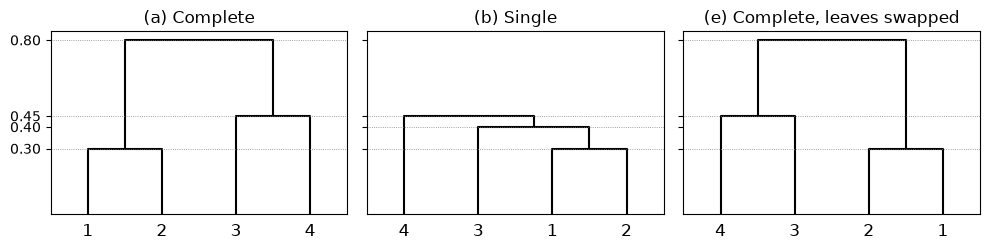

In [12]:
D = np.array([[0, .3, .4, .7], [.3, 0, .5, .8], [.4, .5, 0, .45], [.7, .8, .45, 0]])
Z_c, Z_s = linkage(squareform(D), "complete"), linkage(squareform(D), "single")
Z_e = Z_c.copy(); Z_e[:, [0, 1]] = Z_e[:, [1, 0]]          # swap children at every fusion
fig, ax = plt.subplots(1, 3, figsize=(10, 2.6), sharey=True)
for a, Z, t in zip(ax, [Z_c, Z_s, Z_e], ["(a) Complete", "(b) Single", "(e) Complete, leaves swapped"]):
    dendrogram(Z, labels=[1, 2, 3, 4], ax=a, color_threshold=0, above_threshold_color="k")
    for h in Z[:, 2]: a.axhline(h, ls=":", lw=0.6, c="gray")
    a.set_yticks(sorted(set(Z_c[:, 2]) | set(Z_s[:, 2]))); a.set_title(t)
fig.tight_layout(); fig.savefig(OUT / "p3_dendrograms.png", dpi=150); plt.show()